# eSCALE × DES Y3: deterministic $L_X$–$M$ fits with the three frameworks

Results of `scripts/lx/fit_escale.py` (branch `lx_erosita_splus`). The relation is Pederneiras et al. (2025), Eq. 1:

$$\log_{10}\frac{L_X E(z)^{-1}}{L_{\rm piv}} = \alpha + \beta\log_{10}\frac{M_{200c}E(z)}{M_{\rm piv}} + \gamma\log_{10}\frac{1+z}{1+z_{\rm piv}},$$

with $L_{\rm piv} = 10^{43.26}$ erg/s, $M_{\rm piv} = 10^{14.1}$ M$_\odot$, $z_{\rm piv} = 0.18$ (sample medians). It is deterministic (no scatter) and is inverted exactly for each cluster's mass.

Model and data:
- concentrations from Diemer & Joyce (2019), not fitted; global miscentring ($f_{\rm mis}$, $\sigma_{\rm off}$); two-halo term;
- flat ΛCDM, $H_0 = 70$, $\Omega_m = 0.3$;
- 1556 eSCALE clusters inside DES, centred on the X-ray peak; DES Y3 metacal sources with $z_s > 1.1 z_l + 0.2$.

| Framework | Data | Likelihood |
|---|---|---|
| joint | each cluster's $\Delta\Sigma$ (6 bins, 0.25–3.98 Mpc), boost-corrected with its stack's $B(R)$ | per-bin Sellentin–Heavens; Gaussian where the variance is the shape-noise floor |
| forward-modelled stacks | 15 stacks (3 $z$ × 5 $L_X/E$), 16 bins 0.16–3.98 Mpc, boost-corrected | Sellentin–Heavens with $N$ = members; model $=\sum_c K_c\Delta\Sigma_c/\sum_c K_c$ |
| two-step | the same 15 stacks, each fitted for $\log M_{200c}$, $f_{\rm mis}$, $\sigma_{\rm off}$ | then weighted least squares of $\log(ME/M_{\rm piv})$ on $\log(\langle L_X/E\rangle/L_{\rm piv})$ and $\log((1+\langle z\rangle)/1.18)$, inverted to $(\alpha,\beta,\gamma)$ |

In [1]:
import numpy as np, pickle, json
import matplotlib.pyplot as plt
from astropy.table import Table
from destacking import lx
lx.set_cosmology()
import xlensing.model as xm
D = '/home/andre/destacking_data/lx_splus_erosita_des'
PIV = lx.Pivots(43.26, 14.1, 0.18)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
cat = Table.read(f'{D}/escale_des_sample.fits')
ST = pickle.load(open(f'{D}/measurement/stacks.pkl', 'rb')); stacks = ST['stacks']; R = ST['radii']
W = np.load(f'{D}/measurement/weights.npz')
TS = json.load(open(f'{D}/fits/twostep.json'))
def post(name):
    a = np.load(f'{D}/fits/{name}.npz'); return a['samples'], a['weights'], [str(n) for n in a['param_order']]
P = {k: post(k) for k in ['joint', 'forward']}
def med(k):
    X, w, n = P[k]; return {nm: float(np.interp(0.5, np.cumsum(w[np.argsort(X[:, j])]), np.sort(X[:, j]))) for j, nm in enumerate(n)}
print('N clusters =', len(cat), '; stacks:', len(stacks))

N clusters = 1556 ; stacks: 15


## 1 — The stacks and the forward-modelled fit

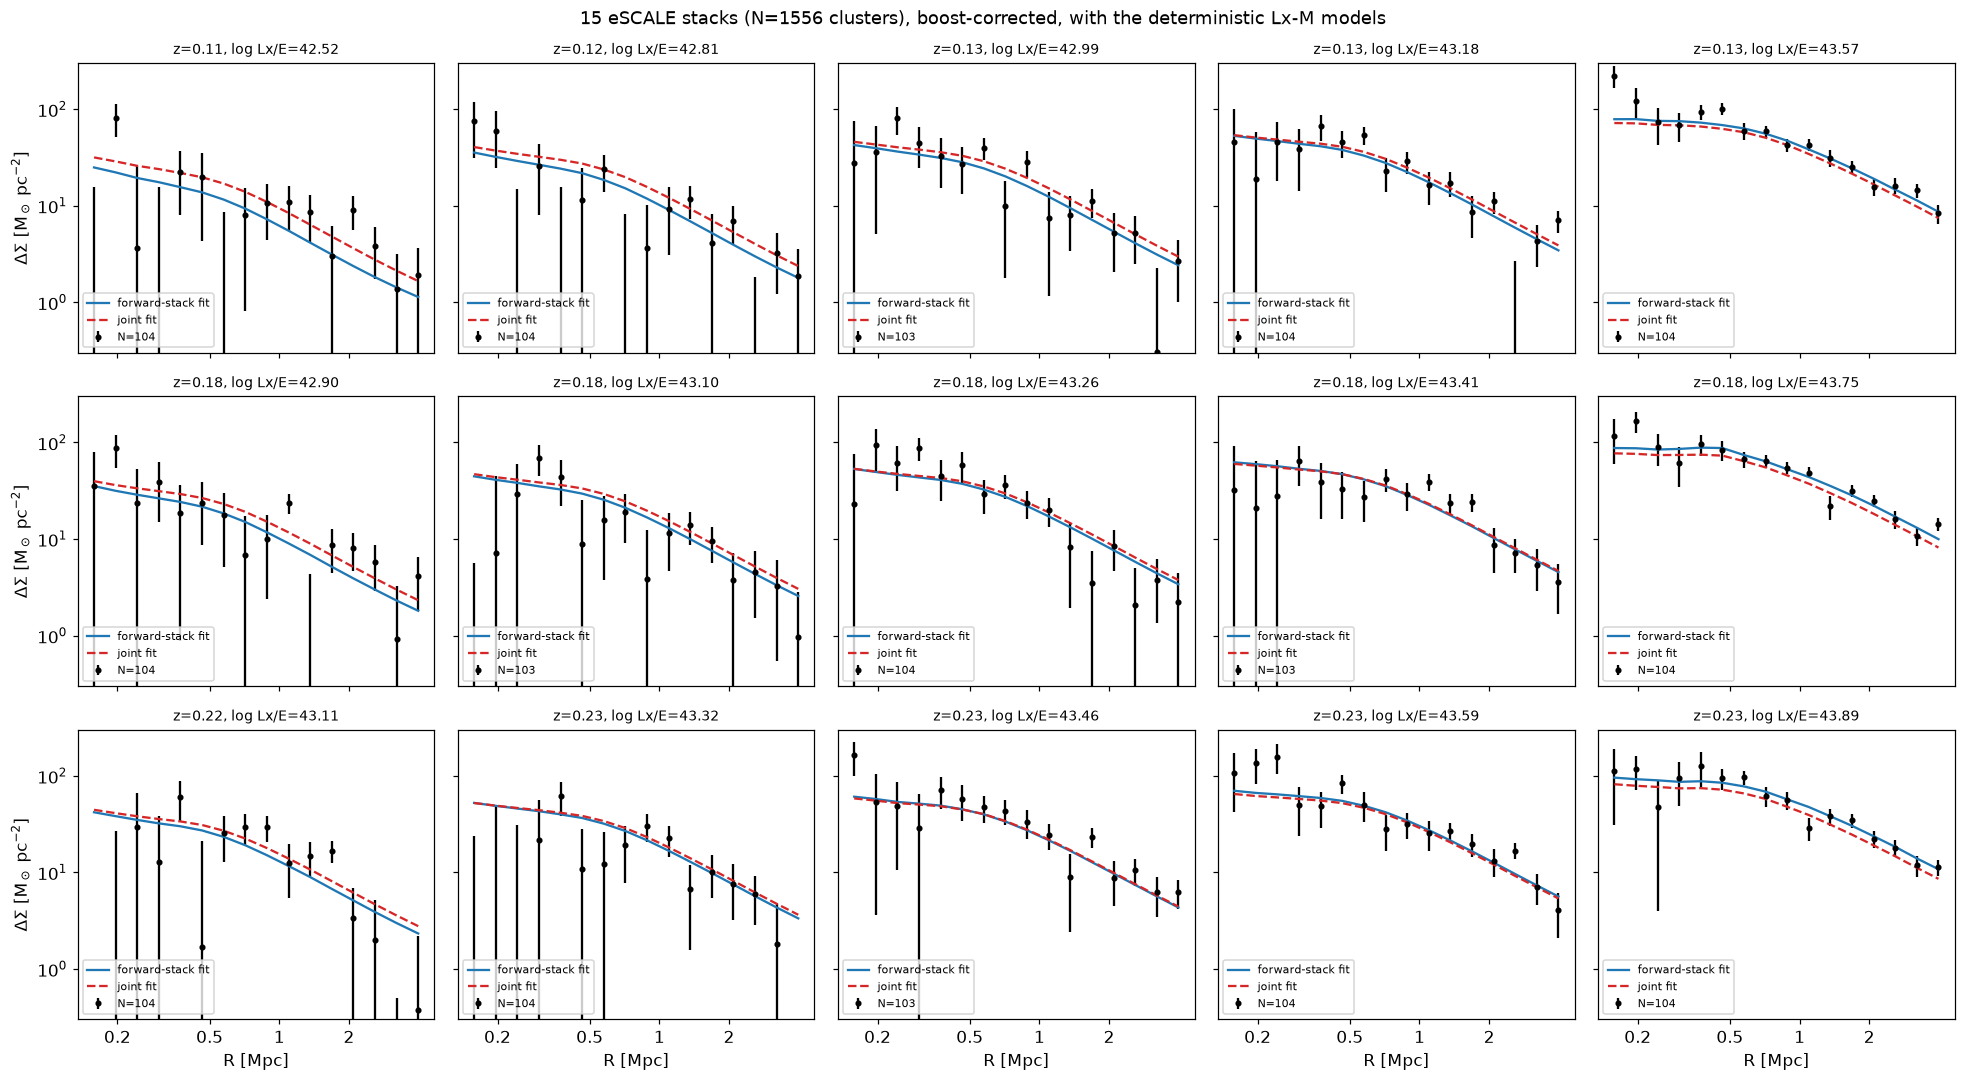

In [2]:
pf, pj = med('forward'), med('joint')
row = {int(i): k for k, i in enumerate(cat['ID'])}
z_all, llx_all = np.asarray(cat['Z'], float), np.log10(np.asarray(cat['LX'], float))
def stack_model(s, p):
    ix = np.array([row[int(i)] for i in s['ids']])
    z, ll = z_all[ix], llx_all[ix]
    ds = lx.nfw_profiles_lx(z, lx.mass_from_lx(ll, z, p['alpha'], p['beta'], p['gamma'], PIV), R,
                            f_mis=p['f_mis'], sigma_off=p['sigma_off'], two_halo=True)
    K = W['K'][ix]
    return (K * ds).sum(0) / K.sum(0)
fig, ax = plt.subplots(3, 5, figsize=(18, 10), sharex=True, sharey=True)
for name, s in sorted(stacks.items()):
    a = ax[s['z_bin'], s['lx_bin']]
    e = np.sqrt(np.diag(s['sigmas_cov']))
    a.errorbar(R, s['sigmas'], yerr=e, fmt='o', ms=3, color='k', label=f'N={s["n_stacked"]}')
    a.plot(R, stack_model(s, pf), color='C0', label='forward-stack fit')
    a.plot(R, stack_model(s, pj), color='C3', ls='--', label='joint fit')
    a.set_xscale('log'); a.set_yscale('log'); a.set_ylim(0.3, 300)
    a.set_xticks([0.2, 0.5, 1, 2]); a.set_xticklabels(['0.2', '0.5', '1', '2']); a.minorticks_off()
    a.set_title(f'z={s["z_mean"]:.2f}, log Lx/E={s["logLxE_mean"]:.2f}', fontsize=9)
    a.legend(fontsize=7, loc='lower left')
for a in ax[-1]: a.set_xlabel('R [Mpc]')
for a in ax[:, 0]: a.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$ pc$^{-2}$]')
fig.suptitle(f'15 eSCALE stacks (N={len(cat)} clusters), boost-corrected, with the deterministic Lx-M models', fontsize=12)
plt.tight_layout(); plt.show()

## 2 — Stack masses against $L_X$

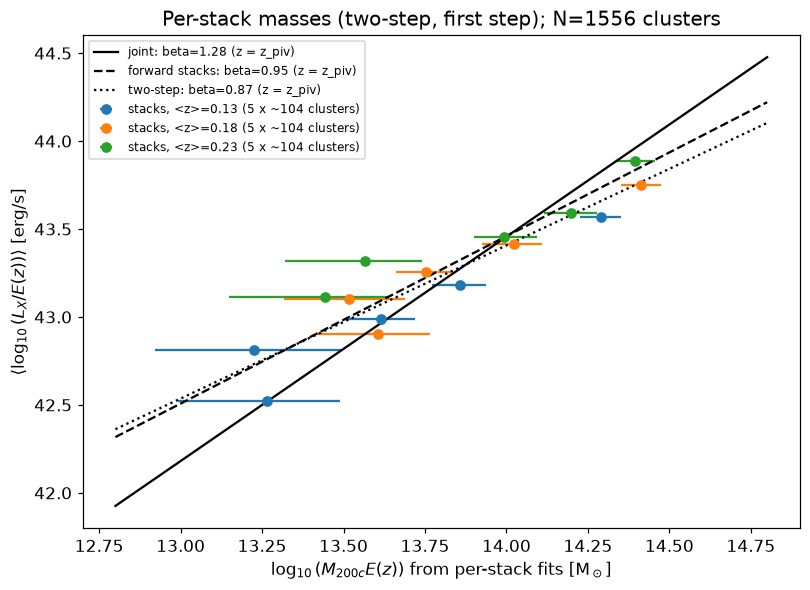

In [3]:
names = sorted(TS['stacks'])
lm = np.array([TS['stacks'][k]['logM'] for k in names]); zs = np.array([TS['stacks'][k]['z'] for k in names])
llxe = np.array([TS['stacks'][k]['logLxE'] for k in names]); Ez = lx.efunc(zs)
fig, ax = plt.subplots(1, 1, figsize=(7.5, 5.5))
for zb, c in zip(range(3), ['C0', 'C1', 'C2']):
    m = np.array([stacks[k]['z_bin'] == zb for k in names])
    y = lm[m, 1] + np.log10(Ez[m])
    ax.errorbar(y, llxe[m], xerr=[lm[m, 1] - lm[m, 0], lm[m, 2] - lm[m, 1]], fmt='o', color=c,
                label=f'stacks, <z>={zs[m].mean():.2f} (5 x ~104 clusters)')
mm = np.linspace(12.8, 14.8, 50)
for lab, p, ls in [('joint', pj, '-'), ('forward stacks', pf, '--'),
                   ('two-step', {k: v[1] for k, v in TS['lx_given_m'].items()}, ':')]:
    ax.plot(mm, PIV.log_L + p['alpha'] + p['beta'] * (mm - PIV.log_M), 'k', ls=ls, label=f'{lab}: beta={p["beta"]:.2f} (z = z_piv)')
ax.set_xlabel(r'$\log_{10}(M_{200c}E(z))$ from per-stack fits [M$_\odot$]'); ax.set_ylabel(r'$\langle\log_{10}(L_X/E(z))\rangle$ [erg/s]')
ax.legend(fontsize=8); ax.set_title(f'Per-stack masses (two-step, first step); N={len(cat)} clusters')
plt.tight_layout(); plt.show()

## 3 — Posteriors

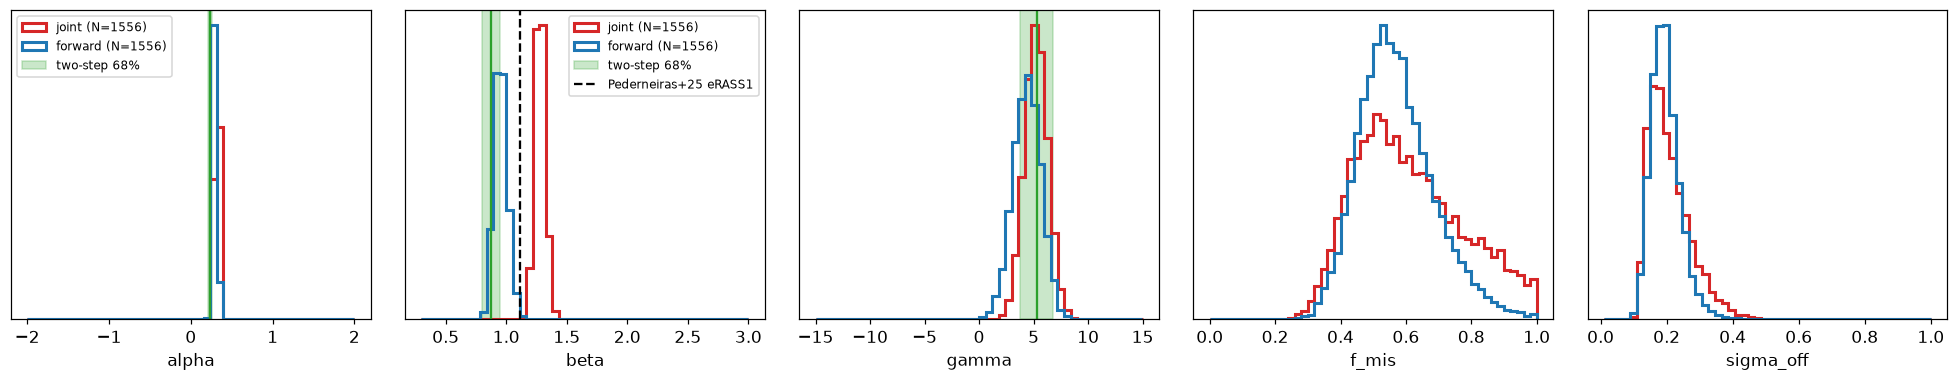

                              joint           forward stacks                 two-step
alpha          +0.324 +0.022/-0.022     +0.294 +0.021/-0.021     +0.234 +0.021/-0.021
beta           +1.275 +0.043/-0.040     +0.952 +0.057/-0.052     +0.871 +0.080/-0.068
gamma          +5.213 +1.054/-1.064     +4.399 +1.249/-1.310     +5.300 +1.494/-1.568
f_mis          +0.585 +0.207/-0.140     +0.559 +0.126/-0.098                        —
sigma_off      +0.195 +0.076/-0.046     +0.191 +0.047/-0.037                        —
two-step regression chi2/dof = 6.8/12


In [4]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
for k, c in [('joint', 'C3'), ('forward', 'C0')]:
    X, w, n = P[k]
    for j, nm in enumerate(n):
        ax[j].hist(X[:, j], bins=50, weights=w, histtype='step', lw=2, color=c, density=True,
                   label=f'{k} (N={len(cat)})')
for j, nm in enumerate(['alpha', 'beta', 'gamma']):
    lo, me, hi = TS['lx_given_m'][nm]
    ax[j].axvspan(lo, hi, color='C2', alpha=0.25, label='two-step 68%'); ax[j].axvline(me, color='C2')
ax[1].axvline(1.11, color='k', ls='--', label='Pederneiras+25 eRASS1')
for a, nm in zip(ax, P['joint'][2]):
    a.set_xlabel(nm); a.set_yticks([])
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'{"":10s} {"joint":>24s} {"forward stacks":>24s} {"two-step":>24s}')
for nm in ['alpha', 'beta', 'gamma', 'f_mis', 'sigma_off']:
    row_ = []
    for k in ['joint', 'forward']:
        X, w, n = P[k]; j = n.index(nm); o = np.argsort(X[:, j]); lo, me, hi = np.interp([.16, .5, .84], np.cumsum(w[o]), X[o, j])
        row_.append(f'{me:+.3f} +{hi-me:.3f}/-{me-lo:.3f}')
    t = TS['lx_given_m'].get(nm); row_.append('—' if t is None else f'{t[1]:+.3f} +{t[2]-t[1]:.3f}/-{t[1]-t[0]:.3f}')
    print(f'{nm:10s} ' + ' '.join(f'{r:>24s}' for r in row_))
print(f'two-step regression chi2/dof = {TS["chi2"]:.1f}/{TS["dof"]}')

## 4 — Status

These are **deterministic** fits: no intrinsic or measurement scatter, and no selection. The selection notebook (`lx_selection_modelling.ipynb`) shows on eSCALE-like mocks that a deterministic fit of this sample is biased, in the normalisation, the slope and especially the redshift term, because the eRASS1 flux limit and the optical selection act on scattered quantities. The large $\gamma$ found here by all three frameworks is consistent with that, and should not be read as evolution of the relation. The disagreement in $\beta$ between the joint and the stacked fits is also expected when scatter is left out; the joint fit is the framework most exposed to it. The next step replaces the deterministic mass with the per-cluster weights $w_{ck}(\theta)$ in all three frameworks.